# 01 – Exploratory Data Analysis

What does the data tell us about default risk before any modeling?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/cs-training.csv")
df = df.drop(columns=["Unnamed: 0"])

print(df.shape)
df.head()

(150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 1. Overview

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.07,0.25,0.0,0.00,0.00,0.00,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.05,249.76,0.0,0.03,0.15,0.56,50708.0
age,150000.0,52.30,14.77,0.0,41.00,52.00,63.00,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.42,4.19,0.0,0.00,0.00,0.00,98.0
DebtRatio,150000.0,353.01,2037.82,0.0,0.18,0.37,0.87,329664.0
MonthlyIncome,120269.0,6670.22,14384.67,0.0,3400.00,5400.00,8249.00,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.45,5.15,0.0,5.00,8.00,11.00,58.0
NumberOfTimes90DaysLate,150000.0,0.27,4.17,0.0,0.00,0.00,0.00,98.0
NumberRealEstateLoansOrLines,150000.0,1.02,1.13,0.0,0.00,1.00,2.00,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.24,4.16,0.0,0.00,0.00,0.00,98.0


In [4]:
tasa_default = df["SeriousDlqin2yrs"].mean()
print(f"Default rate: {tasa_default:.2%}")
print(df["SeriousDlqin2yrs"].value_counts())

Default rate: 6.68%
SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64


### Key findings – Overview

- **Dataset:** 150,000 borrowers and 10 features (Give Me Some Credit, Kaggle).
- **Target:** the default rate is **6.68%**, so classes are highly imbalanced.
- **Missing values:** `MonthlyIncome` (~20%) and `NumberOfDependents` (~3%).
- **Values that make no economic sense:**
    - `NumberOfTime30-59DaysPastDueNotWorse`, `NumberOfTime60-89DaysPastDueNotWorse` and `NumberOfTimes90DaysLate` reach **98**: impossible counts within 2 years, likely special codes (96/98).
    - `RevolvingUtilizationOfUnsecuredLines` reaches **50,708**, when it should be between 0 and 1.
    - `DebtRatio` reaches **329,664**, which suggests it is not a ratio for some borrowers.
    - `age` has a minimum of **0**, which is impossible for a borrower. The maximum of 109 is extreme but plausible.

These issues are analyzed in Section 3 before any modeling.

## 2. Missing values

In [5]:
faltantes = df.isnull().mean().sort_values(ascending=False)*100
faltantes.round(2)

MonthlyIncome                           19.82
NumberOfDependents                       2.62
SeriousDlqin2yrs                         0.00
age                                      0.00
RevolvingUtilizationOfUnsecuredLines     0.00
DebtRatio                                0.00
NumberOfTime30-59DaysPastDueNotWorse     0.00
NumberOfOpenCreditLinesAndLoans          0.00
NumberOfTimes90DaysLate                  0.00
NumberRealEstateLoansOrLines             0.00
NumberOfTime60-89DaysPastDueNotWorse     0.00
dtype: float64

In [6]:
default_por_faltante = df.groupby(df["MonthlyIncome"].isnull())["SeriousDlqin2yrs"].mean()
default_por_faltante.index = ["Income reported", "Income missing"]
(default_por_faltante * 100).round(2)

Income reported    6.95
Income missing     5.61
Name: SeriousDlqin2yrs, dtype: float64

In [7]:
default_por_faltante = df.groupby(df["NumberOfDependents"].isnull())["SeriousDlqin2yrs"].mean()
default_por_faltante.index = ["Dependents reported", "Dependents missing"]
(default_por_faltante * 100).round(2)

Dependents reported    6.74
Dependents missing     4.56
Name: SeriousDlqin2yrs, dtype: float64

In [8]:
pd.crosstab(df["MonthlyIncome"].isnull(), df["NumberOfDependents"].isnull())

NumberOfDependents,False,True
MonthlyIncome,,
False,120269,0
True,25807,3924


### Key findings – Missing values

- **Missing:** `MonthlyIncome` 19.82% and `NumberOfDependents` 2.62%.
- **Missingness is informative, not random:** borrowers who do not report their income default *less* (5.61%) than those who do (6.95%). The same happens with dependents (4.56% vs. 6.74%).
- **Implication for modeling:** imputing the median alone would hide this signal. We will impute **and** add a 0/1 indicator (`income_missing`) so the model can learn from it.

## 3. Anomalies

In [9]:
print("Borrowers with age 0:", (df["age"] == 0).sum())

Borrowers with age 0: 1


In [10]:
mora = ["NumberOfTime30-59DaysPastDueNotWorse",
        "NumberOfTime60-89DaysPastDueNotWorse",
        "NumberOfTimes90DaysLate"]

for col in mora:
    print(col)
    print(df.loc[df[col] >= 90, col].value_counts())
    print()

NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
98    264
96      5
Name: count, dtype: int64

NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
98    264
96      5
Name: count, dtype: int64

NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
98    264
96      5
Name: count, dtype: int64



In [11]:
codigos = df["NumberOfTimes90DaysLate"] >= 90
print("Borrowers with codes 96/98:", codigos.sum())
print(f"Default rate with codes: {df.loc[codigos, 'SeriousDlqin2yrs'].mean():.2%}")
print(f"Default rate without codes: {df.loc[~codigos, 'SeriousDlqin2yrs'].mean():.2%}")

Borrowers with codes 96/98: 269
Default rate with codes: 54.65%
Default rate without codes: 6.60%


In [12]:
util = df["RevolvingUtilizationOfUnsecuredLines"]

grupos_util = pd.cut(util, bins=[-0.01, 1, 10, util.max()],
                     labels=["0-1 (normal)", "1-10", "> 10"])

resumen_util = df.groupby(grupos_util)["SeriousDlqin2yrs"].agg(["count", "mean"])
resumen_util["mean"] = (resumen_util["mean"] * 100).round(2)
resumen_util

,count,mean
RevolvingUtilizationOfUnsecuredLines,,
0-1 (normal),146679,5.99
1-10,3080,39.61
> 10,241,7.05


In [13]:
df.groupby(df["MonthlyIncome"].isnull())["DebtRatio"].median()

MonthlyIncome
False       0.296023
True     1159.000000
Name: DebtRatio, dtype: float64

### Key findings – Anomalies

| Anomaly | Borrowers | Default rate | Treatment (notebook 02) |
|---|---|---|---|
| `age` = 0 | 1 | – | Drop (single invalid record) |
| Past-due counts coded 96/98 | 269 | **54.65%** (vs. 6.60%) | Keep the borrowers, add a `special_code` flag and replace the code with 0 |
| `RevolvingUtilization` between 1 and 10 | 3,080 | **39.61%** (vs. 5.99%) | Keep: over-limit borrowers are a real high-risk signal |
| `RevolvingUtilization` > 10 | 241 | 7.05% | Treat as invalid: flag and replace (they behave like normal borrowers, not like extreme users) |
| `DebtRatio` when income is missing | 29,731 | – | Median of 1,159 vs. 0.30 when income is reported: it is an amount, not a ratio. Handle together with the `income_missing` flag |

- **Codes 96/98 are the same 269 borrowers in the three past-due variables**, and they default 8× more than the rest. Dropping them (as in the original thesis) would hide the riskiest group from the model.
- **Utilization is not monotonic:** risk jumps above 1 (over-limit), but values above 10 behave like normal borrowers, which suggests data errors rather than real usage.

## 4. Default rate by variable

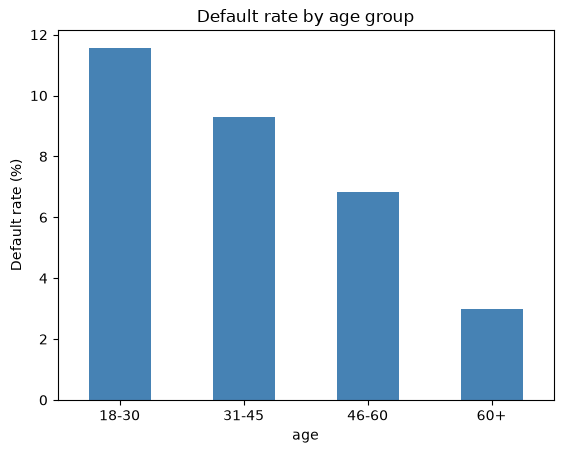

In [14]:
grupos_edad = pd.cut(df["age"], bins=[18, 30, 45, 60, 110],
                     labels=["18-30", "31-45", "46-60", "60+"])

tasa_edad = df.groupby(grupos_edad)["SeriousDlqin2yrs"].mean() * 100

tasa_edad.plot(kind="bar", color="steelblue")
plt.title("Default rate by age group")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=0)
plt.show()

In [15]:
def tasa_por_grupo(df, columna, n_grupos=5):
    """Default rate (%) by quantile groups of a numeric variable."""
    grupos = pd.qcut(df[columna], q=n_grupos, duplicates="drop")
    tasa = df.groupby(grupos)["SeriousDlqin2yrs"].mean() * 100

    tasa.plot(kind="bar", color="steelblue")
    plt.title(f"Default rate by {columna}")
    plt.ylabel("Default rate (%)")
    plt.xticks(rotation=45)
    plt.show()
    return tasa.round(2)

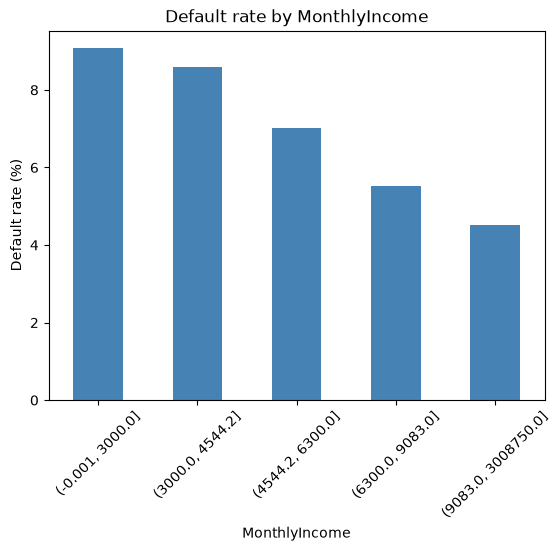

MonthlyIncome
(-0.001, 3000.0]       9.08
(3000.0, 4544.2]       8.60
(4544.2, 6300.0]       7.01
(6300.0, 9083.0]       5.53
(9083.0, 3008750.0]    4.50
Name: SeriousDlqin2yrs, dtype: float64

In [16]:
tasa_por_grupo(df, "MonthlyIncome")

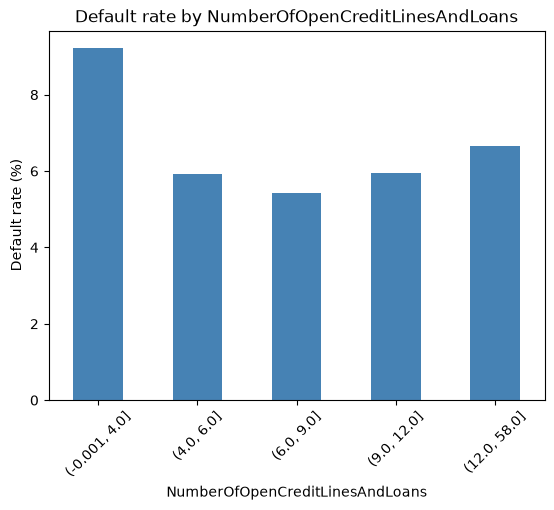

NumberOfOpenCreditLinesAndLoans
(-0.001, 4.0]    9.22
(4.0, 6.0]       5.93
(6.0, 9.0]       5.43
(9.0, 12.0]      5.96
(12.0, 58.0]     6.67
Name: SeriousDlqin2yrs, dtype: float64

In [17]:
tasa_por_grupo(df, "NumberOfOpenCreditLinesAndLoans")

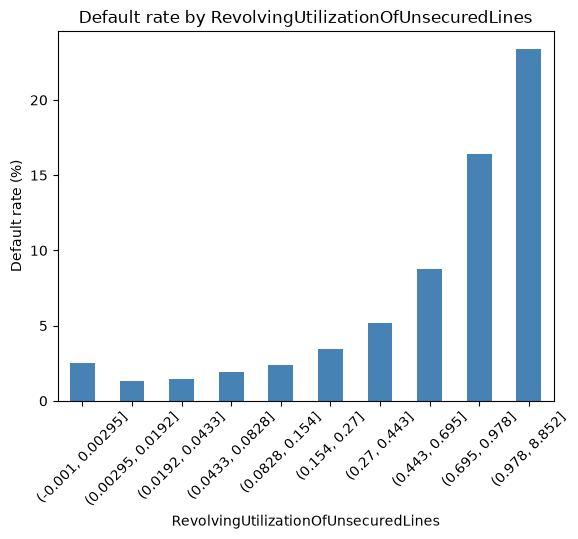

RevolvingUtilizationOfUnsecuredLines
(-0.001, 0.00295]     2.52
(0.00295, 0.0192]     1.35
(0.0192, 0.0433]      1.42
(0.0433, 0.0828]      1.91
(0.0828, 0.154]       2.37
(0.154, 0.27]         3.47
(0.27, 0.443]         5.21
(0.443, 0.695]        8.75
(0.695, 0.978]       16.44
(0.978, 8.852]       23.40
Name: SeriousDlqin2yrs, dtype: float64

In [18]:
tasa_por_grupo(df[df["RevolvingUtilizationOfUnsecuredLines"] <= 10],
               "RevolvingUtilizationOfUnsecuredLines", n_grupos=10)

### Key findings – Default rate by variable

- **Age:** the default rate decreases with age, from [X%] (18–30) to [Y%] (60+). Possibly because older borrowers have higher and more stable income.
- **Monthly income:** the default rate decreases steadily as income increases, from **9.08%** in the lowest quintile to **4.50%** in the highest.
- **Open credit lines and loans:** U-shaped relationship. The default rate is **9.22%** for borrowers with 4 or fewer lines (limited credit history), reaches its minimum of **5.43%** with 7–9 lines and rises again to **6.67%** above 12 (possible over-indebtedness). A linear model will not capture this shape on its own.
- **Revolving utilization:** the default rate rises from **1.35%** for very low utilization to **23.40%** in the top decile. The increase is not linear: it accelerates above ~0.7 (8.75% → 16.44% → 23.40%). Borrowers close to their limit have little room to absorb unexpected expenses.

## 5. Correlations

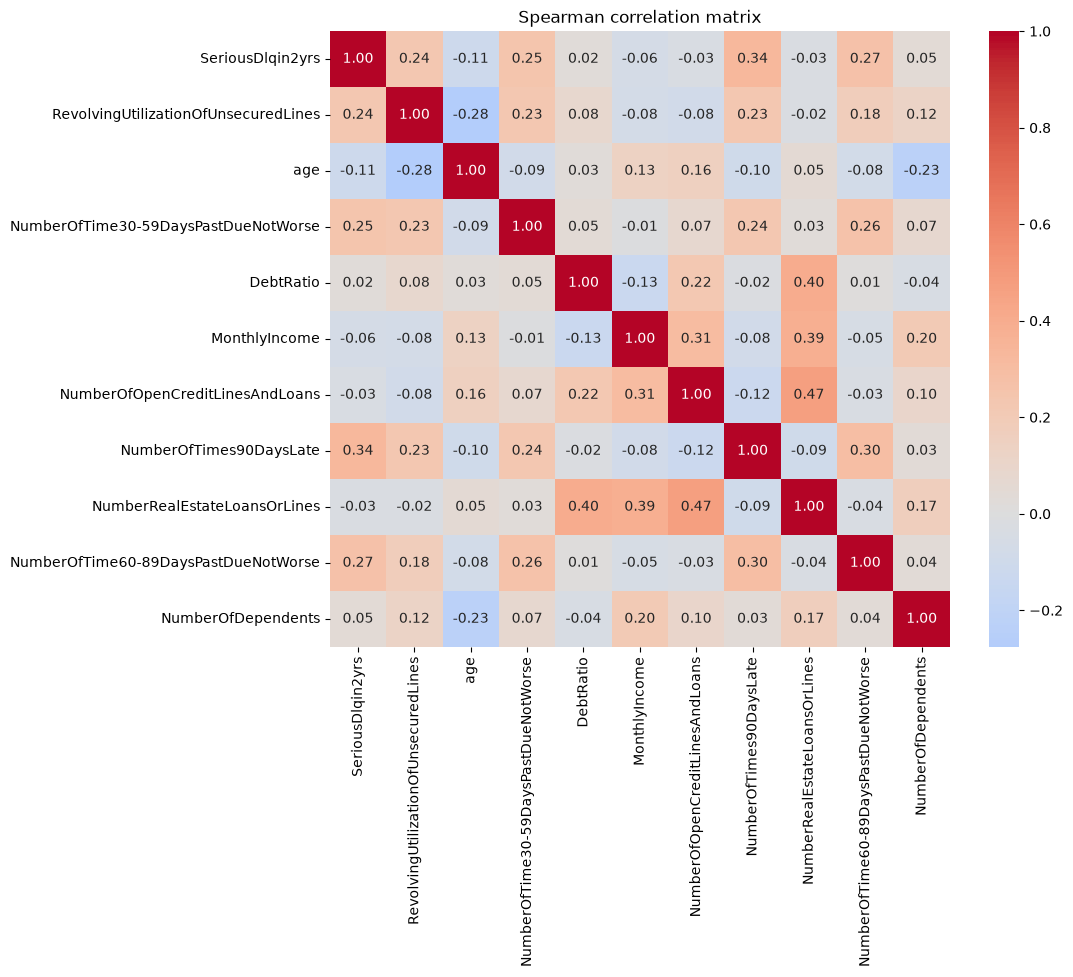

In [19]:
import seaborn as sns

# Excluimos los códigos 96/98 para que no distorsionen las correlaciones
df_corr = df[df["NumberOfTimes90DaysLate"] < 90]

corr = df_corr.corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation matrix")
plt.show()

### Key findings – Correlations

- **Strongest relationships with default** (Spearman): 90+ days late (**0.34**), 60–89 days past due (**0.27**), 30–59 days past due (**0.25**) and revolving utilization (**0.24**). Past delinquency is the best predictor of future default.
- **No severe multicollinearity:** no pair of features exceeds 0.5. The highest are open credit lines vs. real estate loans (0.47), debt ratio vs. real estate loans (0.40) and income vs. real estate loans (0.39).
- **Correlations are low overall (max 0.34), which is normal in credit risk:** no single variable predicts default well; the model works by combining them.
- **Correlation does not capture non-monotonic patterns:** open credit lines show a correlation of −0.03 with default, despite the clear U-shape found in Section 4. Features should not be discarded based on low correlation alone.
- Spearman was used instead of Pearson because it relies on ranks and is robust to the extreme outliers found in Section 3.